# Model state dtype — `float32` vs `uint8`, side by side

`running_gaussian` stores its per-pixel mean and variance as **`uint8`** (2 bytes
per pixel) instead of the **`float32`** (8 bytes per pixel) it used originally —
600 KB → 150 KB of persistent state at QVGA, which is what the Alif port needs.
The update is integer Q8 fixed point with `int32` intermediates, so it is
bit-identical to `sign_of_life_cpp/src/BackgroundModel.cpp`.

Quantisation is not free, and this notebook is where the cost is inspected by
hand. It runs **the same pipeline twice** — identical in every parameter except
`state_dtype` — over the same frames, and shows:

1. the **parameters**, with the two arms differing in one field only,
2. a per-case **stage grid**: each arm's foreground and final mask side by side,
   plus a **disagreement map** colouring which arm claimed which pixel,
3. **evaluation** against the CDNET groundtruth for both arms, with the delta,
4. per-frame **Sign-of-Life** flags for both arms and their agreement — the flag
   is the actual deliverable, so it matters more than the mask F-measure,
5. the **model state** itself: bytes per pixel, and how far the two background
   estimates have drifted apart.

Structure and conventions follow `pipeline_experiments.ipynb`; the parameters
cell is again the single place to change the experiment.

> **Reading the result.** The quantised mean cannot make sub-unit updates, so it
> lags the scene slightly; that inflates the variance, which raises the detection
> threshold and costs **recall**. Precision is essentially untouched. Watch the
> disagreement map: the losses are thin erosions at object boundaries, not
> whole missed objects — which is why the Sign-of-Life flag survives almost
> intact. The full analysis is in
> `models_complexity_ranking.md` § *uint8 model state*.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scr import PipelineConfig, SignOfLifePipeline
from scr.config import (
    BGSConfig,
    BlobConfig,
    DenoiseMethod,
    FeatureConfig,
    FeatureKind,
    Implementation,
    PreprocessConfig,
    ShadowConfig,
    SignOfLifeConfig,
)
from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks
from IPython.display import Markdown, display

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

## 1. Parameters

Everything below is shared by **both** arms; `STATE_DTYPES` is the only axis that
varies, and `build_config` threads it through `BGSConfig.backend_params` into
`RunningGaussianAverage(state_dtype=...)`. Nothing else about the pipeline
changes between the two runs, so every difference downstream is attributable to
the state dtype alone.

`DATASET_ROOT` defaults to the **full-rate `data` tree** rescaled to QVGA rather
than the 0.1-fps tree `pipeline_experiments.ipynb` uses: the decimated tree
exposes only 3–4 labelled frames per case, far too few to compare two models
that differ by a couple of percent. The full sequences (1250 / 1189 frames) take
roughly a minute per case for both arms and reproduce the figures quoted in
`models_complexity_ranking.md`.

In [2]:
# ---- Dataset -------------------------------------------------------------
# Full-rate CDNET tree, rescaled to QVGA on the fly. Set DATASET_ROOT to one of
# the pre-built 0.1-fps trees (and RESIZE = None) for a quick smoke run, at the
# cost of only a handful of scored frames.
DATASET_ROOT = Path("data")
CASES = ["busStation", "canoe"]
RESIZE = (320, 240)               # (width, height); None = the tree's own size
MAX_FRAMES = None                 # cap frames per case for a faster pass

# ---- The comparison axis -------------------------------------------------
# The two model-state layouts. float32 is the original 8 B/px state, kept
# selectable for exactly this kind of reference run; uint8 is the 2 B/px state
# the C++ / Alif port implements.
STATE_DTYPES = ["float32", "uint8"]
BYTES_PER_PIXEL = {"float32": 8, "uint8": 2}   # mean (C=1) + variance

# ---- Layer 0: preprocessing ----------------------------------------------
DENOISE = DenoiseMethod.GAUSSIAN
IMPLEMENTATION = Implementation.NATIVE   # pure-NumPy path, mirrors the C++ port

# ---- Layer 2: feature transform + HSV shadow veto ------------------------
FEATURE = FeatureKind.GRAY
SHADOW = ShadowConfig(
    enabled=True,
    value_ratio_min=0.40,
    value_ratio_max=0.95,
    saturation_delta_max=40.0,
    hue_delta_max=12.0,
    implementation=IMPLEMENTATION,
)

# ---- Layer 1: background model -------------------------------------------
BACKEND = "running_gaussian"
ALPHA = 0.10        # NOTE: the uint8 mean needs alpha > ~0.071 or it stops
                    # tracking (see section 5); 0.1 clears it, 0.005 does not.

# ---- Layer 3: morphology + area gate -------------------------------------
BLOB = BlobConfig(
    min_area=150,
    open_kernel=3,
    close_kernel=7,
    implementation=IMPLEMENTATION,
)
SOL_AREA_THRESHOLD = 500

# ---- Visualisation / scoring ---------------------------------------------
GRID_MAX_FRAMES = 5
FG_THRESHOLD = 127

# Palette: categorical slots 1 and 2 of the reference data-viz palette (blue /
# orange), and its blue-red diverging pair for the disagreement map. Validated
# for colourblind separation, so the two arms stay distinguishable everywhere.
COLOURS = {"float32": "#2a78d6", "uint8": "#eb6834"}
AGREE_FG = "#8a8880"      # both arms called it foreground
ONLY_FP32 = "#2a78d6"     # float32 only -- foreground the uint8 arm missed
ONLY_UINT8 = "#e34948"    # uint8 only   -- foreground the uint8 arm added


def build_config(state_dtype: str) -> PipelineConfig:
    """Assemble the shared PipelineConfig for one model-state dtype."""
    return PipelineConfig(
        preprocess=PreprocessConfig(resize=RESIZE, denoise=DENOISE),
        feature=FeatureConfig(kind=FEATURE),
        shadow=SHADOW,
        bgs=BGSConfig(
            backend=BACKEND,
            learning_rate=ALPHA,
            implementation=IMPLEMENTATION,
            backend_params={"state_dtype": state_dtype},
        ),
        blob=BLOB,
        sign_of_life=SignOfLifeConfig(area_threshold=SOL_AREA_THRESHOLD),
    )


print("Model :", IMPLEMENTATION.value, BACKEND, f"(alpha={ALPHA})")
print("Arms  :", " vs ".join(STATE_DTYPES))
print("Input :", DATASET_ROOT, "->", CASES, f"(resize={RESIZE or 'as read'})")

Model : native running_gaussian (alpha=0.1)
Arms  : float32 vs uint8
Input : data -> ['busStation', 'canoe'] (resize=(320, 240))


## 2. Run both arms

Both pipelines see the **same decoded frame** in the same order, so the only
source of divergence is the model state. Each arm keeps its own foreground mask,
final mask, blobs and Sign-of-Life flag per frame; the pipelines themselves are
kept alive after the loop so section 5 can read their learned state.

In [3]:
def discover_frames(case: str) -> list[Path]:
    directory = DATASET_ROOT / case / "input"
    paths = sorted(p for p in directory.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
    return paths[:MAX_FRAMES] if MAX_FRAMES else paths


def run_case(case: str) -> tuple[list[dict], dict]:
    """Run every arm over one case in lockstep on identical frames."""
    pipelines = {d: SignOfLifePipeline.from_config(build_config(d)) for d in STATE_DTYPES}
    records: list[dict] = []
    for path in discover_frames(case):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            continue
        record = {"number": frame_number(path), "name": path.name}
        for dtype, pipeline in pipelines.items():
            result = pipeline.process(image)
            record[dtype] = {
                "foreground": result.foreground,
                "filtered": result.filtered_mask,
                "blobs": result.blobs,
                "sign_of_life": result.sign_of_life,
            }
        record["input"] = result.frame.bgr   # identical across arms (Layer 0)
        records.append(record)
    return records, pipelines


results, pipelines = {}, {}
for case in CASES:
    results[case], pipelines[case] = run_case(case)
    height, width = results[case][0]["input"].shape[:2]
    print(f"{case}: {len(results[case])} frames x {len(STATE_DTYPES)} arms at {width}x{height}")

busStation: 1250 frames x 2 arms at 320x240
canoe: 1189 frames x 2 arms at 320x240


## 3. Stage grid per case

One row per sampled frame. Frames are drawn from those where **either** arm
detected something — an evenly-spaced sample over the whole sequence would mostly
show the empty warm-up.

| Column | Content |
| --- | --- |
| **Input** | Preprocessed frame, identical for both arms |
| **`float32` foreground** | Model output after the shadow veto, reference arm |
| **`uint8` foreground** | Same, quantised-state arm |
| **Disagreement** | Where the two foregrounds differ, coloured by which arm claimed the pixel |
| **`float32` final** | After morphology + area gate |
| **`uint8` final** | Same, quantised-state arm |

In the disagreement column, grey is foreground **both** arms agree on, blue is
foreground only `float32` found (what quantisation **lost**) and red is
foreground only `uint8` found (what it **added**). A predominantly blue fringe
hugging object edges is the expected signature of the recall loss.

In [4]:
COLUMN_TITLES = [
    "Input",
    "float32 foreground",
    "uint8 foreground",
    "Disagreement",
    "float32 final",
    "uint8 final",
]


def to_rgb(hex_colour: str) -> np.ndarray:
    hex_colour = hex_colour.lstrip("#")
    return np.array([int(hex_colour[i:i + 2], 16) for i in (0, 2, 4)], dtype=np.uint8)


def disagreement_map(reference: np.ndarray, candidate: np.ndarray) -> np.ndarray:
    """Colour each pixel by which arm called it foreground.

    White = neither, grey = both, blue = float32 only, red = uint8 only.
    """
    ref = reference > FG_THRESHOLD
    cand = candidate > FG_THRESHOLD
    canvas = np.full((*ref.shape, 3), 255, dtype=np.uint8)
    canvas[ref & cand] = to_rgb(AGREE_FG)
    canvas[ref & ~cand] = to_rgb(ONLY_FP32)
    canvas[~ref & cand] = to_rgb(ONLY_UINT8)
    return canvas


def sample_rows(records: list[dict], k: int) -> list[dict]:
    """Evenly sample up to k frames, preferring frames with detections."""
    active = [r for r in records if any(r[d]["blobs"] for d in STATE_DTYPES)]
    pool = active or records
    if len(pool) <= k:
        return pool
    index = np.linspace(0, len(pool) - 1, k).round().astype(int)
    return [pool[i] for i in index]


def show_grid(case: str, records: list[dict]) -> None:
    rows = sample_rows(records, GRID_MAX_FRAMES)
    fig, axes = plt.subplots(len(rows), len(COLUMN_TITLES),
                             figsize=(19, 3.0 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, record in enumerate(rows):
        panels = [
            record["input"][:, :, ::-1],                     # BGR -> RGB
            record["float32"]["foreground"],
            record["uint8"]["foreground"],
            disagreement_map(record["float32"]["foreground"],
                             record["uint8"]["foreground"]),
            record["float32"]["filtered"],
            record["uint8"]["filtered"],
        ]
        for c, image in enumerate(panels):
            ax = axes[r][c]
            if image.ndim == 3:
                ax.imshow(image)
            else:
                ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(COLUMN_TITLES[c], fontsize=11)
            if c == 0:
                ax.set_ylabel(f"frame #{record['number']}", fontsize=10)
    handles = [
        plt.Line2D([], [], marker="s", linestyle="", markersize=9,
                   markerfacecolor=colour, markeredgecolor="none", label=label)
        for colour, label in (
            (AGREE_FG, "both arms"),
            (ONLY_FP32, "float32 only (lost by uint8)"),
            (ONLY_UINT8, "uint8 only (added by uint8)"),
        )
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, -0.012))
    fig.suptitle(f"{case} — float32 vs uint8 model state ({BACKEND}, alpha={ALPHA})",
                 fontsize=13)
    fig.tight_layout()
    plt.show()

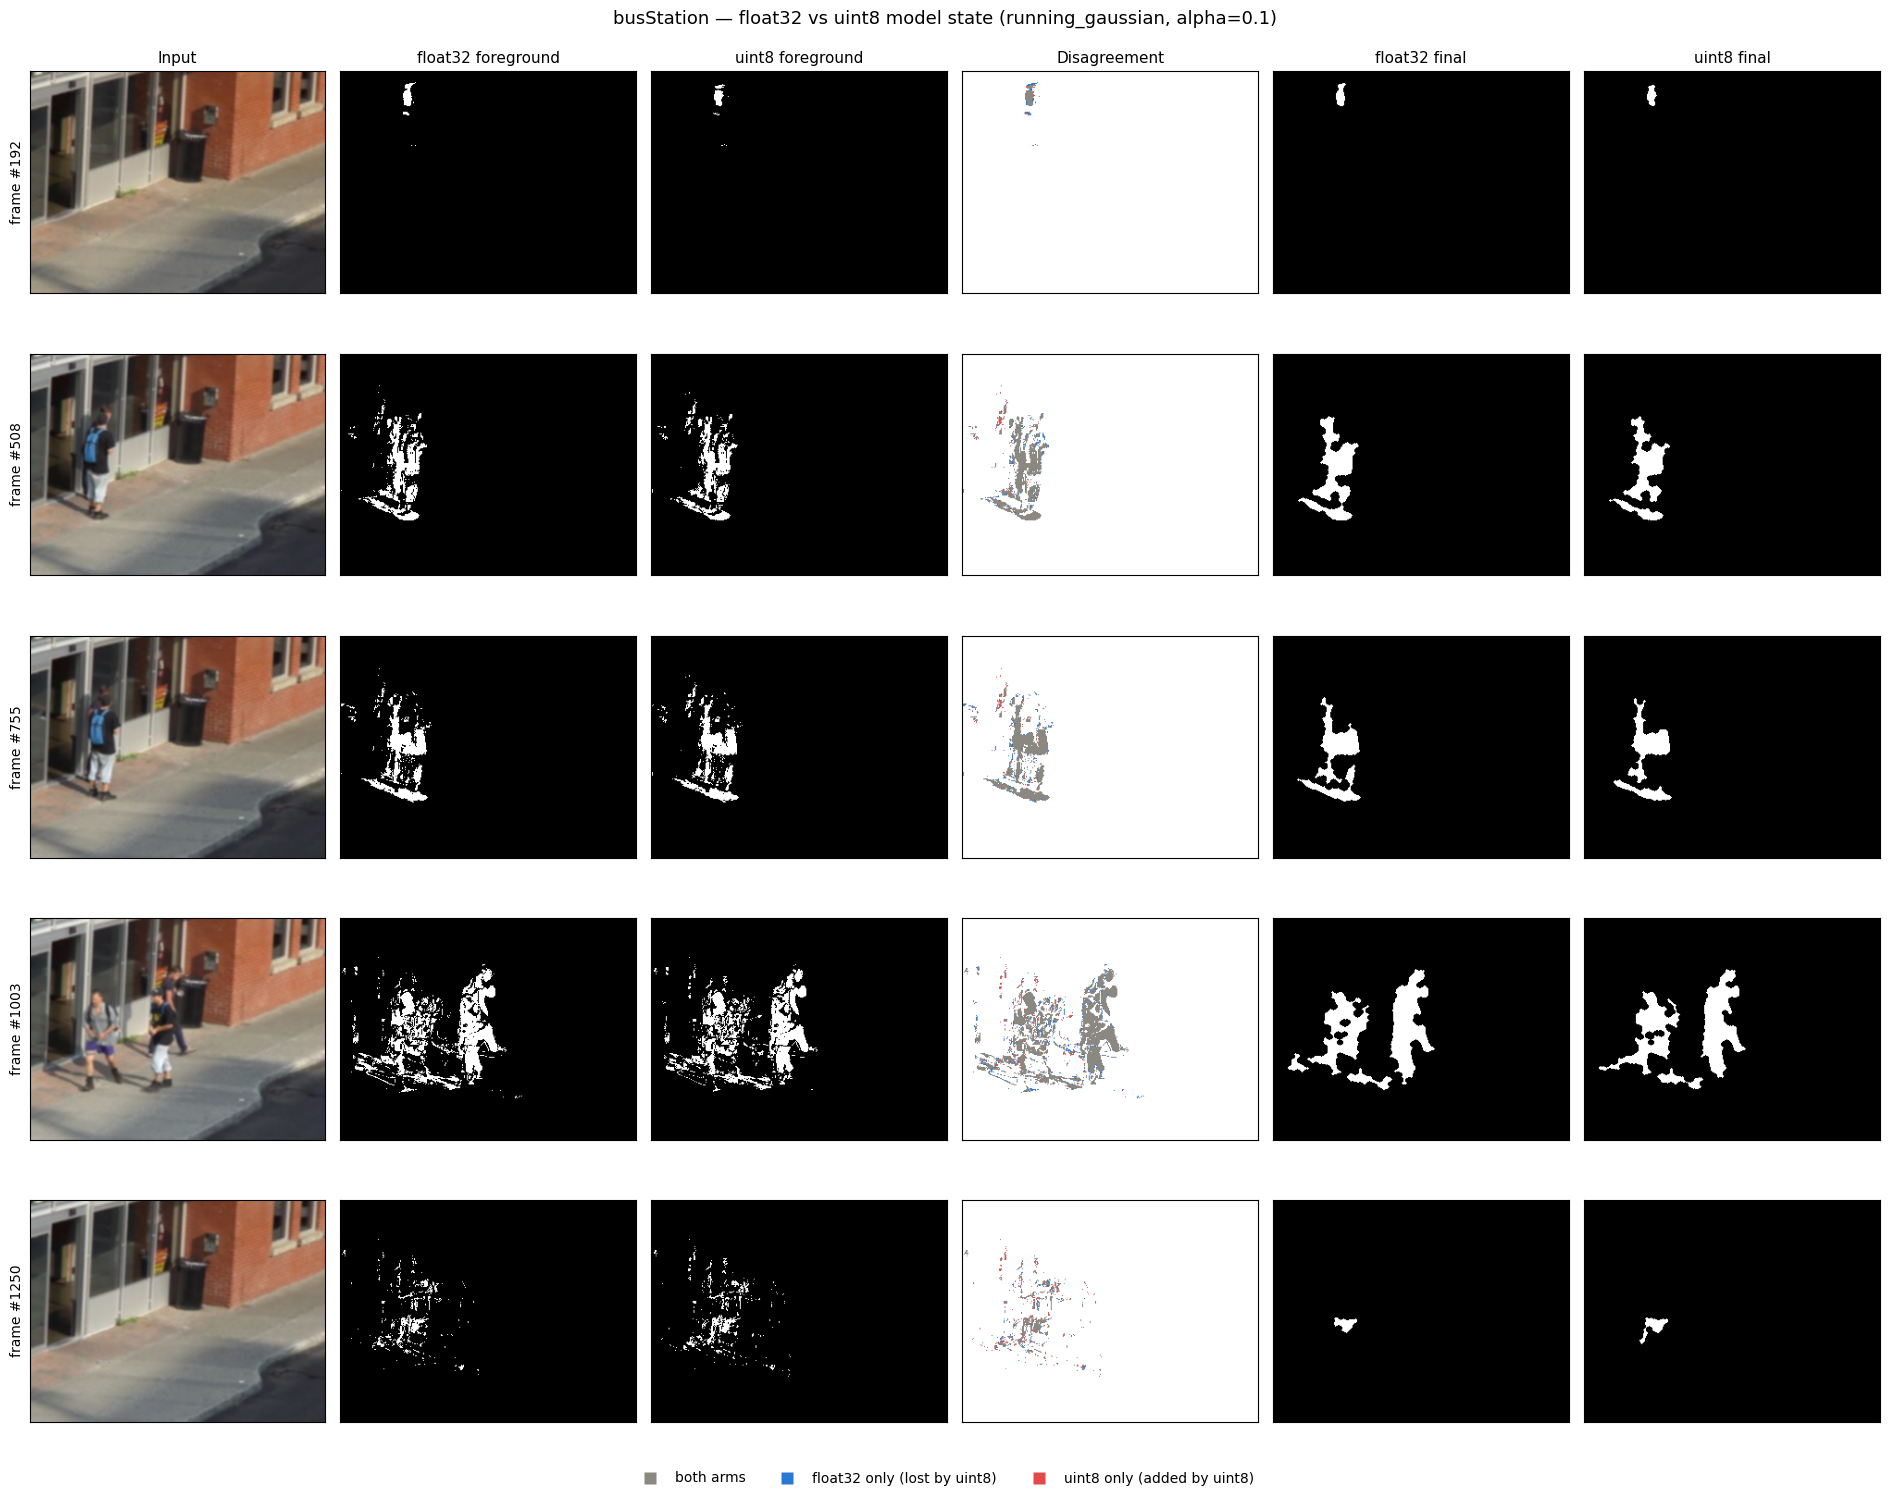

In [5]:
show_grid('busStation', results['busStation'])

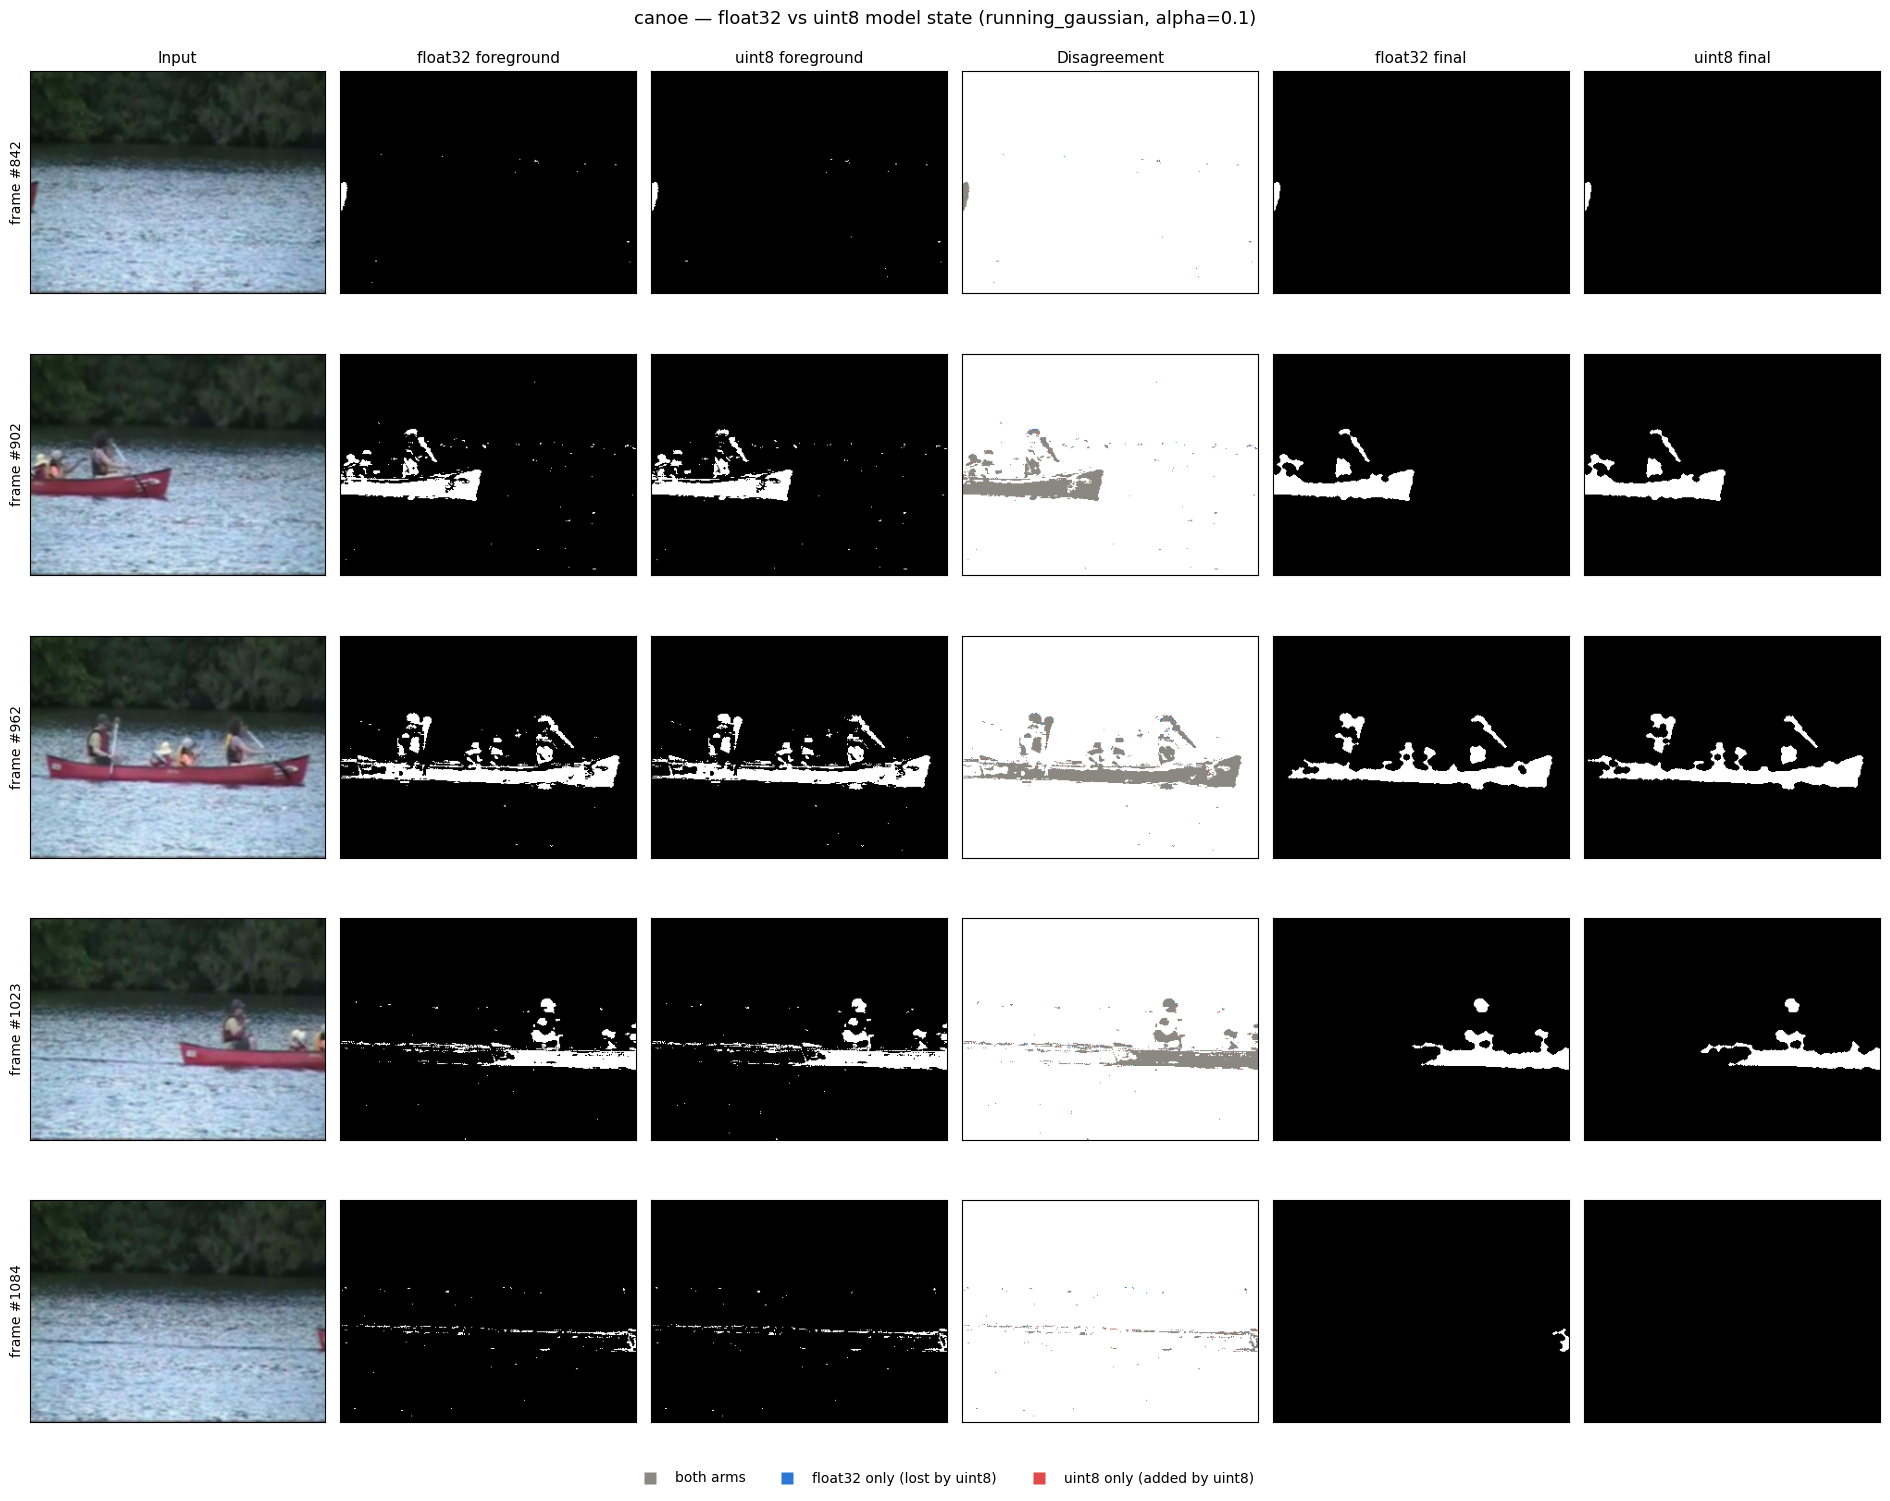

In [6]:
show_grid('canoe', results['canoe'])

## 4. Evaluation

Both arms are scored against the CDNET groundtruth under the standard protocol:
only pixels whose groundtruth is exactly `0` or `255` count, so shadow (50),
unknown (170) and outside-ROI (85) pixels are ignored — which also means frames
outside the temporal ROI drop out on their own, with no explicit range to keep in
sync.

Two masks are scored per arm: the raw **foreground** (model output, directly
comparable to the Phase-1 model sweep) and the **filtered** mask after morphology
and the area gate, which is what the pipeline actually emits.

In [7]:
def evaluate_case(case: str, records: list[dict], dtype: str, mask_key: str) -> dict:
    groundtruth = index_masks(DATASET_ROOT / case / "groundtruth")
    tp = fp = fn = tn = frames = 0
    for record in records:
        number = record["number"]
        if number not in groundtruth:
            continue
        gt = cv2.imread(str(groundtruth[number]), cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(gt, record[dtype][mask_key], FG_THRESHOLD)
        if sum(counts) == 0:          # groundtruth is all void for this frame
            continue
        tp, fp, fn, tn = tp + counts[0], fp + counts[1], fn + counts[2], tn + counts[3]
        frames += 1
    result = EvaluationResult.from_counts(tp, fp, fn, tn, frames)
    return {
        "case": case,
        "mask": mask_key,
        "state dtype": dtype,
        "eval frames": result.frames,
        "precision": result.precision,
        "recall": result.recall,
        "F-measure": result.f_measure,
        "IoU": result.iou,
    }


scores = pd.DataFrame([
    evaluate_case(case, results[case], dtype, mask_key)
    for case in CASES
    for mask_key in ("foreground", "filtered")
    for dtype in STATE_DTYPES
])
display(
    scores.style.format(
        {"precision": "{:.3f}", "recall": "{:.3f}", "F-measure": "{:.3f}", "IoU": "{:.3f}"}
    ).hide(axis="index").background_gradient(
        subset=["F-measure"], cmap="RdYlGn", vmin=0, vmax=1
    )
)

case,mask,state dtype,eval frames,precision,recall,F-measure,IoU
busStation,foreground,float32,951,0.745,0.527,0.617,0.446
busStation,foreground,uint8,951,0.729,0.504,0.596,0.425
busStation,filtered,float32,951,0.887,0.572,0.695,0.533
busStation,filtered,uint8,951,0.884,0.531,0.663,0.496
canoe,foreground,float32,390,0.864,0.664,0.751,0.601
canoe,foreground,uint8,390,0.866,0.665,0.752,0.603
canoe,filtered,float32,390,0.989,0.686,0.810,0.680
canoe,filtered,uint8,390,0.989,0.687,0.811,0.682


### 4.1 What quantisation changed

The table above is the lookup; this is the answer. Each bar is
`uint8 − float32` for one metric, so **left of zero is a regression**. The
expected shape is a recall bar clearly negative, a precision bar near zero — the
signature of a lagging mean inflating the variance and raising the detection
threshold, rather than of a model that has stopped working.

case,mask,precision,recall,F-measure,IoU
busStation,filtered,-0.0022,-0.0417,-0.0323,-0.0370
busStation,foreground,-0.0153,-0.0228,-0.0210,-0.0216
canoe,filtered,+0.0007,+0.0012,+0.0011,+0.0015
canoe,foreground,+0.0017,+0.0009,+0.0012,+0.0016


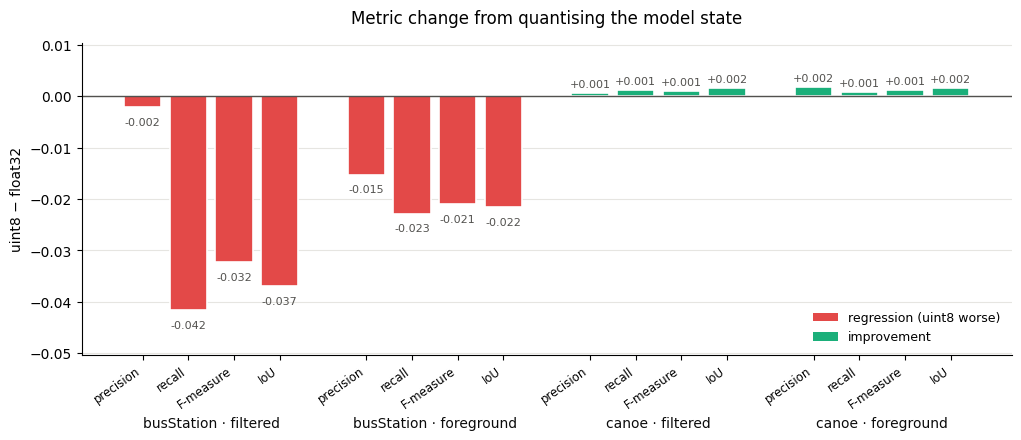

In [8]:
wide = scores.pivot_table(
    index=["case", "mask"], columns="state dtype",
    values=["precision", "recall", "F-measure", "IoU"],
)
deltas = pd.DataFrame({
    metric: wide[metric]["uint8"] - wide[metric]["float32"]
    for metric in ("precision", "recall", "F-measure", "IoU")
}).reset_index()

display(
    deltas.style.format({m: "{:+.4f}" for m in ("precision", "recall", "F-measure", "IoU")})
    .hide(axis="index")
    .background_gradient(
        subset=["precision", "recall", "F-measure", "IoU"],
        cmap="RdBu", vmin=-0.10, vmax=0.10,
    )
)

METRICS = ["precision", "recall", "F-measure", "IoU"]
IMPROVED = "#1baf7a"

# Every bar carries its metric name on the axis: colour encodes the sign only,
# so identity must not rest on bar position.
positions, values, tick_labels, group_centres, group_labels = [], [], [], [], []
cursor = 0.0
for _, row in deltas.iterrows():
    start = cursor
    for metric in METRICS:
        positions.append(cursor)
        values.append(row[metric])
        tick_labels.append(metric)
        cursor += 1.0
    group_centres.append((start + cursor - 1.0) / 2)
    group_labels.append(f"{row['case']} · {row['mask']}")
    cursor += 0.9                       # gap keeps the groups visually separate

values = np.array(values)
fig, ax = plt.subplots(figsize=(12, 5.2))
bars = ax.bar(positions, values, 0.82,
              color=[ONLY_UINT8 if v < 0 else IMPROVED for v in values],
              edgecolor="white", linewidth=1.2)
for bar, value in zip(bars, values):
    ax.annotate(f"{value:+.3f}", (bar.get_x() + bar.get_width() / 2, value),
                textcoords="offset points", xytext=(0, 4 if value >= 0 else -13),
                ha="center", fontsize=8, color="#52514e")

ax.axhline(0, color="#52514e", linewidth=1.0)
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, fontsize=8.5, rotation=35, ha="right")
for centre, label in zip(group_centres, group_labels):
    ax.annotate(label, xy=(centre, 0), xycoords=("data", "axes fraction"),
                xytext=(0, -52), textcoords="offset points",
                ha="center", fontsize=10, color="#0b0b0b", annotation_clip=False)
ax.margins(y=0.20)
ax.set_ylabel("uint8 − float32", fontsize=10)
ax.set_title("Metric change from quantising the model state", fontsize=12, pad=14)
handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=ONLY_UINT8, edgecolor="none",
                  label="regression (uint8 worse)"),
    plt.Rectangle((0, 0), 1, 1, facecolor=IMPROVED, edgecolor="none",
                  label="improvement"),
]
ax.legend(handles=handles, frameon=False, fontsize=9, loc="lower right")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(bottom=0.28)
plt.show()

## 5. Per-frame Sign of Life

The mask F-measure is a proxy. The pipeline's actual output is the per-frame
**Sign-of-Life** flag — set when any surviving region has an area
`>= SOL_AREA_THRESHOLD` px — so the honest question is not "how many pixels moved"
but "**how often do the two arms disagree about whether something is there**".

The strip below is one column per frame: the top two rows are each arm's flag,
the bottom row marks the frames where they differ.

case,frames,float32 flagged,uint8 flagged,disagreeing frames,agreement
busStation,1250,802,783,21,98.32%
canoe,1189,227,227,0,100.00%


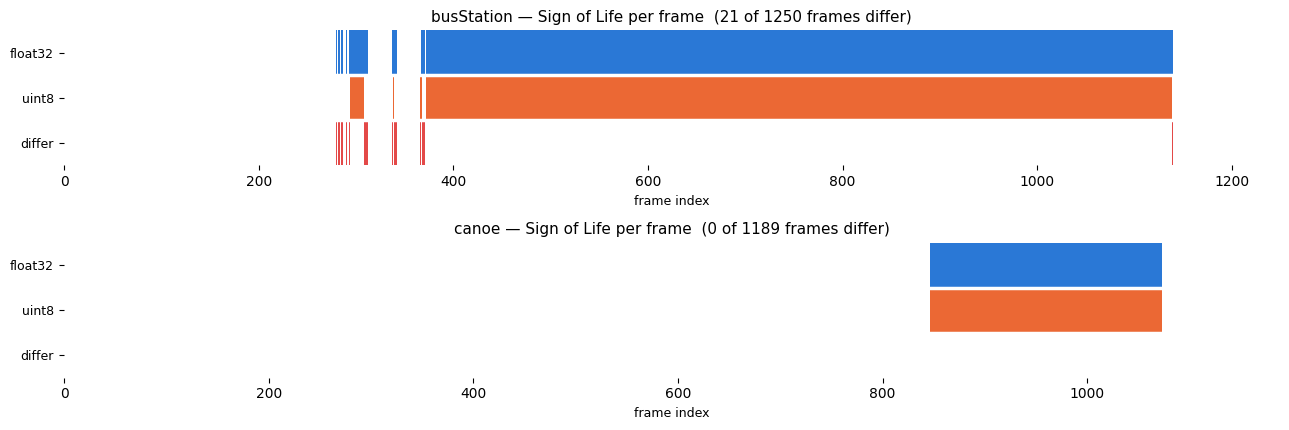

In [9]:
def sol_flags(records: list[dict], dtype: str) -> np.ndarray:
    return np.array([bool(r[dtype]["sign_of_life"]) for r in records])


rows = []
for case in CASES:
    records = results[case]
    reference, candidate = (sol_flags(records, d) for d in STATE_DTYPES)
    disagree = reference != candidate
    rows.append({
        "case": case,
        "frames": len(records),
        "float32 flagged": int(reference.sum()),
        "uint8 flagged": int(candidate.sum()),
        "disagreeing frames": int(disagree.sum()),
        "agreement": 1.0 - disagree.mean(),
    })
agreement = pd.DataFrame(rows)
display(agreement.style.format({"agreement": "{:.2%}"}).hide(axis="index"))

fig, axes = plt.subplots(len(CASES), 1, figsize=(13, 2.2 * len(CASES)))
axes = np.atleast_1d(axes)
for ax, case in zip(axes, CASES):
    records = results[case]
    reference, candidate = (sol_flags(records, d) for d in STATE_DTYPES)
    strip = np.full((3, len(records), 3), 255, dtype=np.uint8)
    strip[0][reference] = to_rgb(COLOURS["float32"])
    strip[1][candidate] = to_rgb(COLOURS["uint8"])
    strip[2][reference != candidate] = to_rgb(ONLY_UINT8)
    ax.imshow(strip, aspect="auto", interpolation="nearest")
    for edge in (0.5, 1.5):                    # keep adjacent fills separated
        ax.axhline(edge, color="white", linewidth=2.5)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["float32", "uint8", "differ"], fontsize=9)
    ax.set_xlabel("frame index", fontsize=9)
    disagree = int((reference != candidate).sum())
    ax.set_title(f"{case} — Sign of Life per frame  "
                 f"({disagree} of {len(records)} frames differ)", fontsize=11)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

### 5.1 The frames that actually differ

Where the flags disagree, the deciding blob is usually sitting near
`SOL_AREA_THRESHOLD` and the quantised arm's slightly eroded mask pushes it under.
The table lists each disagreeing frame with the largest region area each arm
found, so it is easy to see how marginal the call was.

In [10]:
def disagreement_table(case: str, records: list[dict]) -> pd.DataFrame:
    rows = []
    for record in records:
        flags = {d: bool(record[d]["sign_of_life"]) for d in STATE_DTYPES}
        if flags["float32"] == flags["uint8"]:
            continue
        areas = {
            d: max((int(b.area) for b in record[d]["blobs"]), default=0)
            for d in STATE_DTYPES
        }
        rows.append({
            "frame": record["number"],
            "float32 flag": flags["float32"],
            "uint8 flag": flags["uint8"],
            "float32 largest region (px)": areas["float32"],
            "uint8 largest region (px)": areas["uint8"],
            "shortfall vs threshold": min(areas.values()) - SOL_AREA_THRESHOLD,
        })
    return pd.DataFrame(rows)


for case in CASES:
    table = disagreement_table(case, results[case])
    display(Markdown(f"#### {case} — threshold = {SOL_AREA_THRESHOLD} px"))
    if table.empty:
        display(Markdown("_The two arms agree on every frame._"))
    else:
        display(table.style.hide(axis="index"))

#### busStation — threshold = 500 px

frame,float32 flag,uint8 flag,float32 largest region (px),uint8 largest region (px),shortfall vs threshold
280,True,False,520,384,-116
282,True,False,556,454,-46
283,True,False,553,450,-50
285,True,False,505,367,-133
286,True,False,565,416,-84
287,True,False,523,381,-119
291,True,False,537,257,-243
294,True,False,544,430,-70
309,True,False,643,315,-185
310,True,False,589,486,-14


#### canoe — threshold = 500 px

_The two arms agree on every frame._

## 6. The model state itself

The point of the exercise. `bytes/pixel` is measured from the live arrays rather
than assumed, so it stays honest if the representation changes again.

The drift figure is the mean absolute difference between the two arms' learned
background images at the end of the sequence, in grey levels. It is bounded by
the **dead zone**: with an integer mean, an update of `alpha * delta` rounds to
zero whenever `|delta| < 1/(2*alpha)` — 5 grey levels at `alpha = 0.1`. That is
tolerable only because it stays below the smallest distance the model can flag,
`sqrt(threshold * variance_floor)` = 7 grey levels, so a mean frozen inside the
dead zone cannot by itself raise a false positive. **Below `alpha ≈ 0.071` the
ordering reverses and the quantised model stops tracking the scene**; both ports
warn when that is configured.

case,state dtype,mean dtype,variance dtype,bytes/pixel,state (KB),QVGA 320x240 (KB)
busStation,float32,float32,float32,8.0,600,600
busStation,uint8,uint8,uint8,2.0,150,150
canoe,float32,float32,float32,8.0,600,600
canoe,uint8,uint8,uint8,2.0,150,150


**4x smaller** — 600 KB → 150 KB of persistent model state at QVGA.

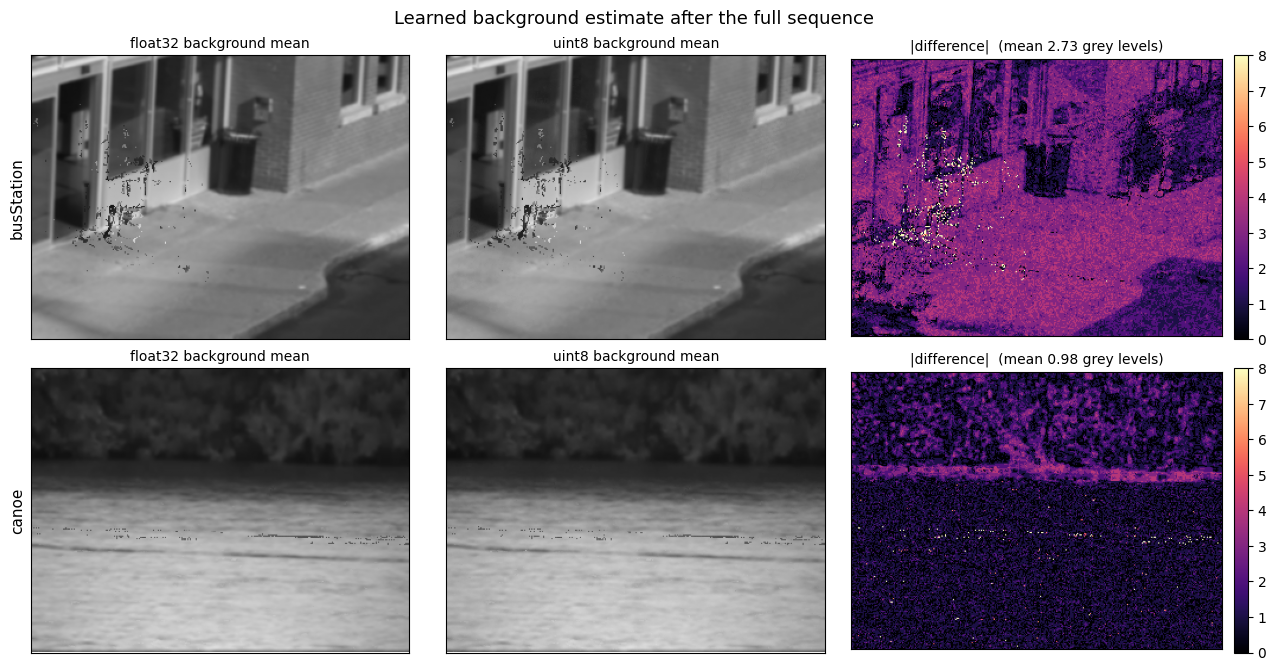

In [11]:
def state_arrays(pipeline: SignOfLifePipeline):
    """Return the model's (mean, variance) arrays.

    Deliberate introspection into the model's private state: measuring the
    storage is the whole point of this section, and no public API exposes the
    variance plane or the mean's dtype (`get_background_image` always renders
    uint8).
    """
    model = pipeline.model.backend.model
    return model._mean, model._variance


rows = []
for case in CASES:
    for dtype in STATE_DTYPES:
        mean, variance = state_arrays(pipelines[case][dtype])
        pixels = mean[:, :, 0].size
        total = mean.nbytes + variance.nbytes
        rows.append({
            "case": case,
            "state dtype": dtype,
            "mean dtype": str(mean.dtype),
            "variance dtype": str(variance.dtype),
            "bytes/pixel": total / pixels,
            "state (KB)": total / 1024,
            "QVGA 320x240 (KB)": BYTES_PER_PIXEL[dtype] * 320 * 240 / 1024,
        })
state = pd.DataFrame(rows)
display(
    state.style.format(
        {"bytes/pixel": "{:.1f}", "state (KB)": "{:.0f}", "QVGA 320x240 (KB)": "{:.0f}"}
    ).hide(axis="index")
)

reduction = BYTES_PER_PIXEL["float32"] / BYTES_PER_PIXEL["uint8"]
display(Markdown(
    f"**{reduction:.0f}x smaller** — "
    f"{BYTES_PER_PIXEL['float32'] * 320 * 240 / 1024:.0f} KB → "
    f"{BYTES_PER_PIXEL['uint8'] * 320 * 240 / 1024:.0f} KB of persistent model "
    f"state at QVGA."
))

fig, axes = plt.subplots(len(CASES), 3, figsize=(13, 3.4 * len(CASES)))
axes = np.atleast_2d(axes)
for r, case in enumerate(CASES):
    backgrounds = {
        d: pipelines[case][d].model.backend.model.get_background_image()
        for d in STATE_DTYPES
    }
    drift = np.abs(backgrounds["float32"].astype(np.int16)
                   - backgrounds["uint8"].astype(np.int16))
    panels = [
        (backgrounds["float32"], "float32 background mean", dict(cmap="gray", vmin=0, vmax=255)),
        (backgrounds["uint8"], "uint8 background mean", dict(cmap="gray", vmin=0, vmax=255)),
        (drift, f"|difference|  (mean {drift.mean():.2f} grey levels)",
         dict(cmap="magma", vmin=0, vmax=8)),
    ]
    for c, (image, title, kwargs) in enumerate(panels):
        ax = axes[r][c]
        rendered = ax.imshow(image, **kwargs)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=10)
        if c == 0:
            ax.set_ylabel(case, fontsize=11)
        if c == 2:
            fig.colorbar(rendered, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Learned background estimate after the full sequence", fontsize=13)
fig.tight_layout()
plt.show()

## Notes

- **Read the Sign-of-Life agreement, not the F-measure.** The mask metric is a
  pixel count; the deliverable is a boolean per frame. The two move very
  differently here, and the flag is the one the product depends on.
- **The loss is recall, and it is structural.** Quantising the *variance* alone
  is nearly free; quantising the *mean* accounts for essentially all of the
  difference. Spending a third byte on a Q8.8 `uint16` mean recovers it
  (0.6950 / 0.8109 F-measure at 3 B/px against 0.695 / 0.810 here), which is the
  trade to revisit if the flag agreement ever degrades — see
  `models_complexity_ranking.md` § *uint8 model state*.
- **`ALPHA` is now a correctness parameter, not just a tuning knob.** Below
  ≈0.071 the quantised mean freezes. Sweeping `ALPHA` downward in this notebook
  will show the `uint8` arm degrading while the `float32` arm keeps working; the
  model logs a warning when it happens rather than failing silently.
- **The C++ port is bit-identical to the `uint8` arm.** Both use the same integer
  Q8 update, so `run_cpp_pipeline.py` output can be diffed against this arm
  directly — any difference comes from Layer 0 (`GaussianBlur` is float and not
  bit-exact with `cv2`), never from the model.
- **The shadow reference is still `float32`** — 12 bytes per pixel, 900 KB at
  QVGA, now the pipeline's largest buffer by a wide margin. It is untouched by
  this change and is the obvious next target.